# 04 · Solution 2: Recursive Feature Elimination (wrapper) + Random Forest

### Feature selection: Recursive Feature Elimination (RFE)
RFE (Guyon et al., 2002, who introduced it with SVMs; Granitto et al., 2006, used it with Random Forest importances as we do here) is a **wrapper** method: it uses a model to judge features.
1. Train a Random Forest on the current feature set.
2. Rank features by the forest's impurity-based importance.
3. Remove the 10 least important features.
4. Repeat until 10 features remain.

The order in which features are removed gives a full ranking. Because the forest is retrained after each removal, importances are re-estimated in the context of the remaining features. RFE therefore partly accounts for interactions and redundancy, which a univariate filter like MI ignores. (Impurity-based importances are known to be biased when features are correlated, so this is an approximation.) The price is many more model fits.

### Classifier: Random Forest
An ensemble of 300 decision trees (Breiman, 2001). Each tree is trained on a bootstrap sample and considers a random subset of features at each split, and the forest predicts by majority vote. It handles non-linear interactions, needs no scaling, and averaging many trees reduces variance. `class_weight="balanced"` handles the smaller neutral class.

### Tuned inside the training actors
- **k** (features kept after RFE): 10 … 190
- **min_samples_leaf**: 1, 3
- **max_features** per split: √k or 20 % of k

**How k is chosen (one-standard-error rule).** For every k, the inner loop records the best macro-F1 over all settings. We then pick the *smallest* k whose score is within one standard error of the overall best (Hastie, Tibshirani & Friedman, *Elements of Statistical Learning*, §7.10). When several subset sizes perform about the same, this prefers the smaller, simpler one, the same idea as the size penalty in the GA. The standard error comes from only 3 inner folds, so it is a rough estimate. We first ran the plain "best inner score" rule. Its results are kept in `results/argmax_rule/` and compared in notebook 06, so the choice of rule is fully transparent.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ser.config import EMOTION_ORDER, FEATURES_CSV
from ser.evaluation import nested_ranked_cv, rank_all, rank_rfe_rf, scores
from ser.features import feature_group
from ser.models import K_GRID, RF_GRID, make_rf
from ser.plots import (SOLUTION_COLORS, plot_confusion, plot_k_curve, plot_selection_frequency,
                       save, set_style)

set_style()
COLOR = SOLUTION_COLORS["S2: RFE + RF"]

df = pd.read_csv(FEATURES_CSV)
META = ["file", "actor", "gender", "emotion_id", "emotion", "intensity", "statement", "repetition"]
FEATURES = [c for c in df.columns if c not in META]
X, y, actors = df[FEATURES].to_numpy(), df["emotion"].to_numpy(), df["actor"].to_numpy()

## 1. Baseline: Random Forest on all 190 features

In [2]:
base = nested_ranked_cv("Baseline RF: all features", X, y, actors, FEATURES, rank_all, make_rf,
                        RF_GRID, k_grid=[len(FEATURES)], files=df.file)
base.save()
base.summary().round(3)

[Baseline RF: all features] fold 1/6 actors [np.int64(1), np.int64(12), np.int64(15), np.int64(24)]: acc=0.588 F1=0.587 k=190 {'min_samples_leaf': 1, 'max_features': 'sqrt'} (30s)


[Baseline RF: all features] fold 2/6 actors [np.int64(6), np.int64(10), np.int64(13), np.int64(19)]: acc=0.446 F1=0.440 k=190 {'min_samples_leaf': 1, 'max_features': 'sqrt'} (20s)


[Baseline RF: all features] fold 3/6 actors [np.int64(7), np.int64(16), np.int64(20), np.int64(23)]: acc=0.542 F1=0.488 k=190 {'min_samples_leaf': 3, 'max_features': 'sqrt'} (20s)


[Baseline RF: all features] fold 4/6 actors [np.int64(4), np.int64(5), np.int64(11), np.int64(18)]: acc=0.442 F1=0.394 k=190 {'min_samples_leaf': 1, 'max_features': 0.2} (28s)


[Baseline RF: all features] fold 5/6 actors [np.int64(9), np.int64(14), np.int64(21), np.int64(22)]: acc=0.500 F1=0.473 k=190 {'min_samples_leaf': 3, 'max_features': 0.2} (22s)


[Baseline RF: all features] fold 6/6 actors [np.int64(2), np.int64(3), np.int64(8), np.int64(17)]: acc=0.588 F1=0.569 k=190 {'min_samples_leaf': 1, 'max_features': 0.2} (23s)


,accuracy,macro_f1,uar,n_features,fit_seconds
mean,0.517,0.492,0.510,190.0,3.835
std,0.066,0.074,0.071,0.0,1.829


## 2. Solution 2: RFE + Random Forest
The RFE ranking is rebuilt from scratch inside every inner and outer training set, so the test actors never influence which features are kept.

In [3]:
s2 = nested_ranked_cv("S2: RFE + RF", X, y, actors, FEATURES, rank_rfe_rf, make_rf,
                      RF_GRID, k_grid=K_GRID, files=df.file)
s2.save()
s2.summary().round(3)

[S2: RFE + RF] fold 1/6 actors [np.int64(1), np.int64(12), np.int64(15), np.int64(24)]: acc=0.588 F1=0.587 k=150 {'min_samples_leaf': 3, 'max_features': 'sqrt'} (160s)


[S2: RFE + RF] fold 2/6 actors [np.int64(6), np.int64(10), np.int64(13), np.int64(19)]: acc=0.421 F1=0.410 k=40 {'min_samples_leaf': 3, 'max_features': 'sqrt'} (155s)


[S2: RFE + RF] fold 3/6 actors [np.int64(7), np.int64(16), np.int64(20), np.int64(23)]: acc=0.562 F1=0.503 k=40 {'min_samples_leaf': 1, 'max_features': 0.2} (158s)


[S2: RFE + RF] fold 4/6 actors [np.int64(4), np.int64(5), np.int64(11), np.int64(18)]: acc=0.375 F1=0.340 k=30 {'min_samples_leaf': 1, 'max_features': 'sqrt'} (154s)


[S2: RFE + RF] fold 5/6 actors [np.int64(9), np.int64(14), np.int64(21), np.int64(22)]: acc=0.454 F1=0.419 k=40 {'min_samples_leaf': 1, 'max_features': 0.2} (261s)


[S2: RFE + RF] fold 6/6 actors [np.int64(2), np.int64(3), np.int64(8), np.int64(17)]: acc=0.592 F1=0.578 k=100 {'min_samples_leaf': 1, 'max_features': 0.2} (177s)


,accuracy,macro_f1,uar,n_features,fit_seconds
mean,0.499,0.473,0.491,66.667,1.695
std,0.094,0.100,0.096,48.028,0.808


In [4]:
s2.folds[["fold", "test_actors", "accuracy", "macro_f1", "uar", "n_features", "params", "select_seconds"]].round(3)

,fold,test_actors,accuracy,macro_f1,uar,n_features,params,select_seconds
0,0,1 12 15 24,0.588,0.587,0.602,150,"{""min_samples_leaf"": 3, ""max_features"": ""sqrt""}",14.064
1,1,6 10 13 19,0.421,0.410,0.430,40,"{""min_samples_leaf"": 3, ""max_features"": ""sqrt""}",15.380
2,2,7 16 20 23,0.562,0.503,0.527,40,"{""min_samples_leaf"": 1, ""max_features"": 0.2}",14.431
3,3,4 5 11 18,0.375,0.340,0.359,30,"{""min_samples_leaf"": 1, ""max_features"": ""sqrt""}",13.791
4,4,9 14 21 22,0.454,0.419,0.441,40,"{""min_samples_leaf"": 1, ""max_features"": 0.2}",18.086
5,5,2 3 8 17,0.592,0.578,0.586,100,"{""min_samples_leaf"": 1, ""max_features"": 0.2}",14.730


## 3. Macro-F1 vs number of RFE-selected features

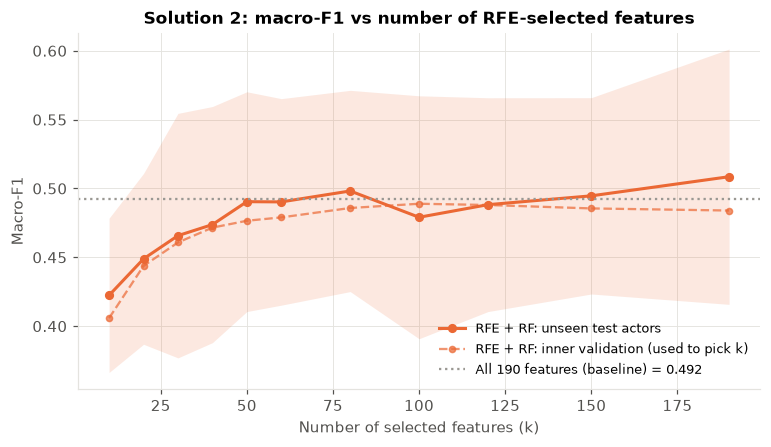

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
plot_k_curve(s2.inner_curve, s2.outer_curve, COLOR, "RFE + RF", baseline=base.folds.macro_f1.mean(), ax=ax)
ax.set_title("Solution 2: macro-F1 vs number of RFE-selected features")
save(fig, "08b_s2_k_curve")
plt.show()

## 4. Confusion matrix (out-of-fold, unseen actors)

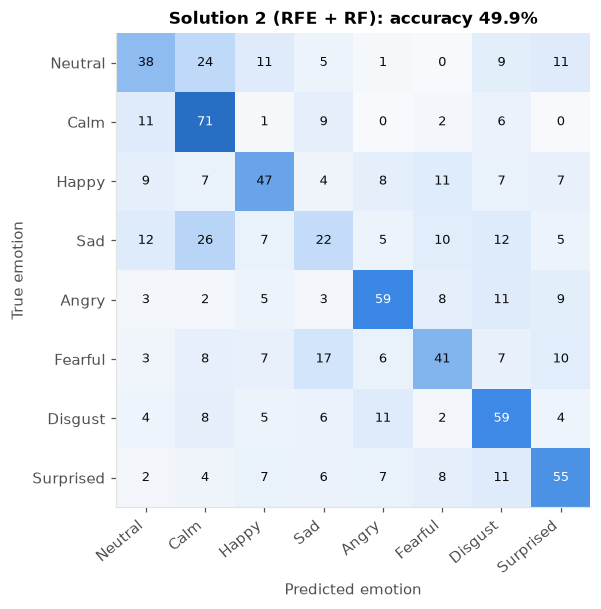

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
plot_confusion(s2.oof.y_true, s2.oof.y_pred, EMOTION_ORDER,
               f"Solution 2 (RFE + RF): accuracy {scores(s2.oof.y_true, s2.oof.y_pred)['accuracy']:.1%}", ax=ax)
save(fig, "10b_s2_confusion")
plt.show()

## 5. Which features survived elimination?

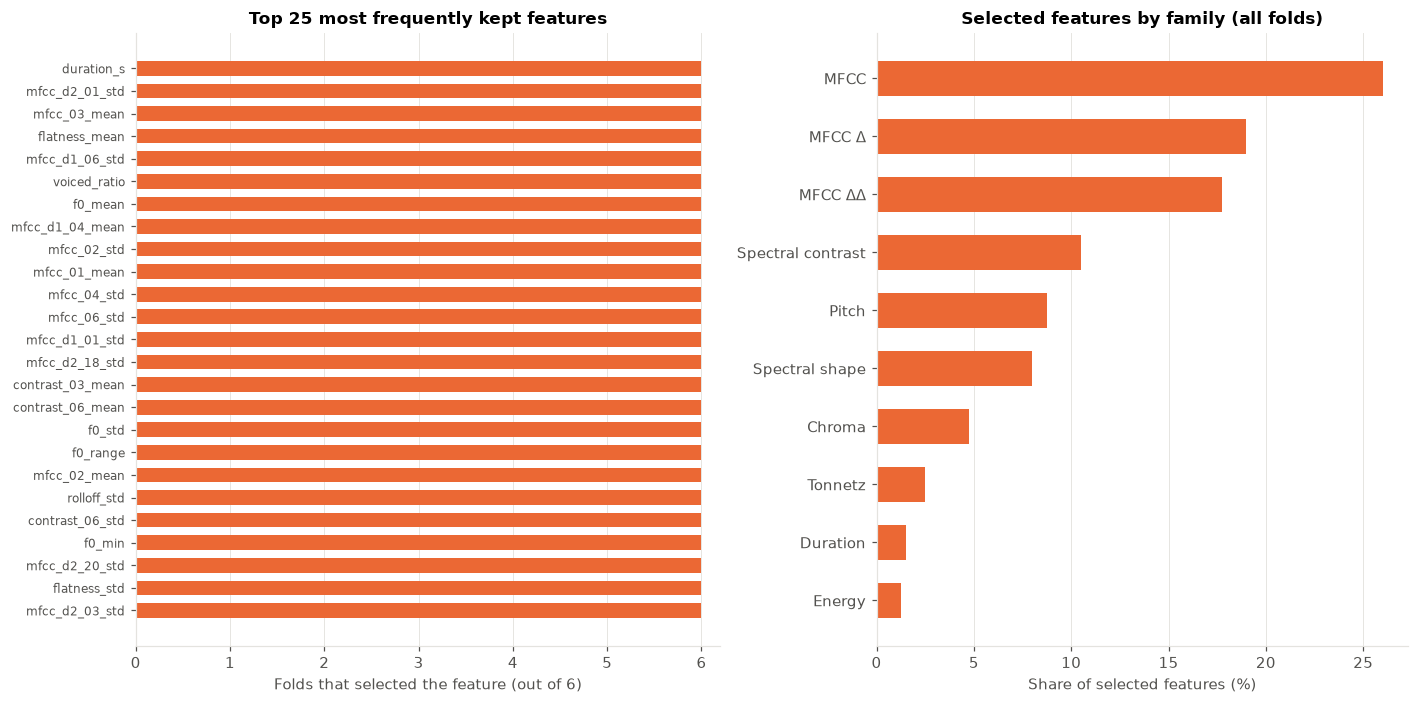

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
plot_selection_frequency(s2.selected, top=25, color=COLOR, title="Top 25 most frequently kept features", ax=axes[0])
fam = pd.Series([feature_group(f) for fold in s2.selected for f in fold]).value_counts(normalize=True) * 100
axes[1].barh(fam.index[::-1], fam.values[::-1], color=COLOR, height=0.6)
axes[1].set_xlabel("Share of selected features (%)")
axes[1].set_title("Selected features by family (all folds)")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "11b_s2_selected_features")
plt.show()

## 6. Summary

In [8]:
summary = pd.concat({"Baseline RF (all 190)": base.summary(), "S2: RFE + RF": s2.summary()})
summary.round(3)

accuracy  macro_f1    uar  n_features  fit_seconds
Baseline RF (all 190) mean     0.517     0.492  0.510     190.000        3.835
                      std      0.066     0.074  0.071       0.000        1.829
S2: RFE + RF          mean     0.499     0.473  0.491      66.667        1.695
                      std      0.094     0.100  0.096      48.028        0.808

In [9]:
d = s2.folds.macro_f1.mean() - base.folds.macro_f1.mean()
print(f"Macro-F1 change from feature selection: {d:+.3f}")
print(f"Features used: 190 -> {s2.folds.n_features.mean():.0f} on average")
print(f"Average RFE ranking time per outer fold: {s2.folds.select_seconds.mean():.1f} s")

Macro-F1 change from feature selection: -0.019
Features used: 190 -> 67 on average
Average RFE ranking time per outer fold: 15.1 s
